## Objectives:
### Clean null Data:

- Identify and handle missing values to ensure a complete dataset.
### Check Data Types (dtype):

- Ensure that all columns have the correct data types for analysis.
### Use pd.describe() to Verify Consistency:

- Check if the summary statistics match expected results (e.g., no negative square footage, reasonable room counts).
### Examine Data Distribution:

- Visualize the distribution of key features to detect outliers and unusual patterns.
### Validate Logical Relationships:

- `id` should be unique.
- `sqft_above` + `sqft_basement` = `sqft_living`.
- `zip_code` should start with `98`, as this is the only area we are analyzing.
### Exporting Cleaned Data:
- Export the cleaned data into a CSV file using the `to_csv` method.

---
## Import

In [36]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [48]:
df = pd.read_csv('Housing.csv')
df['date'] = pd.to_datetime(df['date'])
original_columns = df.columns.to_list()
df['mounth'] = df['date'].dt.month
df['year'] = df['date'].dt.year

---

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21613 non-null  int64         
 1   date           21613 non-null  datetime64[ns]
 2   price          21613 non-null  float64       
 3   bedrooms       21613 non-null  int64         
 4   bathrooms      21613 non-null  float64       
 5   sqft_living    21613 non-null  int64         
 6   sqft_lot       21613 non-null  int64         
 7   floors         21613 non-null  float64       
 8   waterfront     21613 non-null  int64         
 9   view           21613 non-null  int64         
 10  condition      21613 non-null  int64         
 11  grade          21613 non-null  int64         
 12  sqft_above     21613 non-null  int64         
 13  sqft_basement  21613 non-null  int64         
 14  yr_built       21613 non-null  int64         
 15  yr_renovated   2161

### Note
There is no `null` data.

---
## Dtype Fix
Only `bathrooms` and `floors` have a `float` dtype, which is unusual since they should be whole numbers.

In [39]:
df['floors'] = df['floors'].astype(int)
df['bathrooms'] = df['bathrooms'].astype(int)

## pd.describe()

In [40]:
df.describe()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,mounth,year
count,2.161300e+04,21613,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580306e+09,2014-10-29 04:38:01.959931648,5.400886e+05,3.370795,1.749734,2079.899736,1.510697e+04,1.446213,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652,6.574423,2014.322954
min,1.000102e+06,2014-05-02 00:00:00,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000,1.000000,2014.000000
25%,2.123049e+09,2014-07-22 00:00:00,3.219500e+05,3.000000,1.000000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000,4.000000,2014.000000
50%,3.904930e+09,2014-10-16 00:00:00,4.500000e+05,3.000000,2.000000,1910.000000,7.618000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000,6.000000,2014.000000
75%,7.308900e+09,2015-02-17 00:00:00,6.450000e+05,4.000000,2.000000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000,9.000000,2015.000000
max,9.900000e+09,2015-05-27 00:00:00,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.000000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000,12.000000,2015.000000
std,2.876570e+09,NaN,3.671268e+05,0.930105,0.734873,918.440897,4.142051e+04,0.551894,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631,3.115308,0.467616


### Note
#### Minimum Values
- `bedrooms`, `bathrooms`, and `yr_renovated` have a minimum value of `0`. This is strange for `bedrooms` and `bathrooms`, so I will drop these rows.
- For `yr_renovated`, I will combine it with `yr_built` using the following rule: 
    - If `yr_built` < `yr_renovated`, then `yr_built` = `yr_renovated`.
#### Maximum Values:

- `bedrooms` has a maximum value of `33`, which sounds unreasonable.
---


In [41]:
df = df[(df['bedrooms']>0) & (df['bathrooms']>0)]

# Update 'yr_built' to reflect the renovation year if it exists
df['yr_built'] = np.where(df['yr_renovated'] == 0, df['yr_built'], df['yr_renovated'])

In [42]:
df.groupby('bedrooms')['bedrooms'].count()

bedrooms
1      168
2     2733
3     9807
4     6879
5     1601
6      272
7       38
8       13
9        6
10       3
11       1
33       1
Name: bedrooms, dtype: int64

#### Note
The `33` `bedrooms` value stands out significantly compared to the rest, with the next closest value being `11`. Therefore, I will simply remove the row with `33` `bedrooms`, as it is most likely an outlier or a data entry error.

In [43]:
df = df[df['bedrooms'] < 33]

---
## Examine Data Distribution

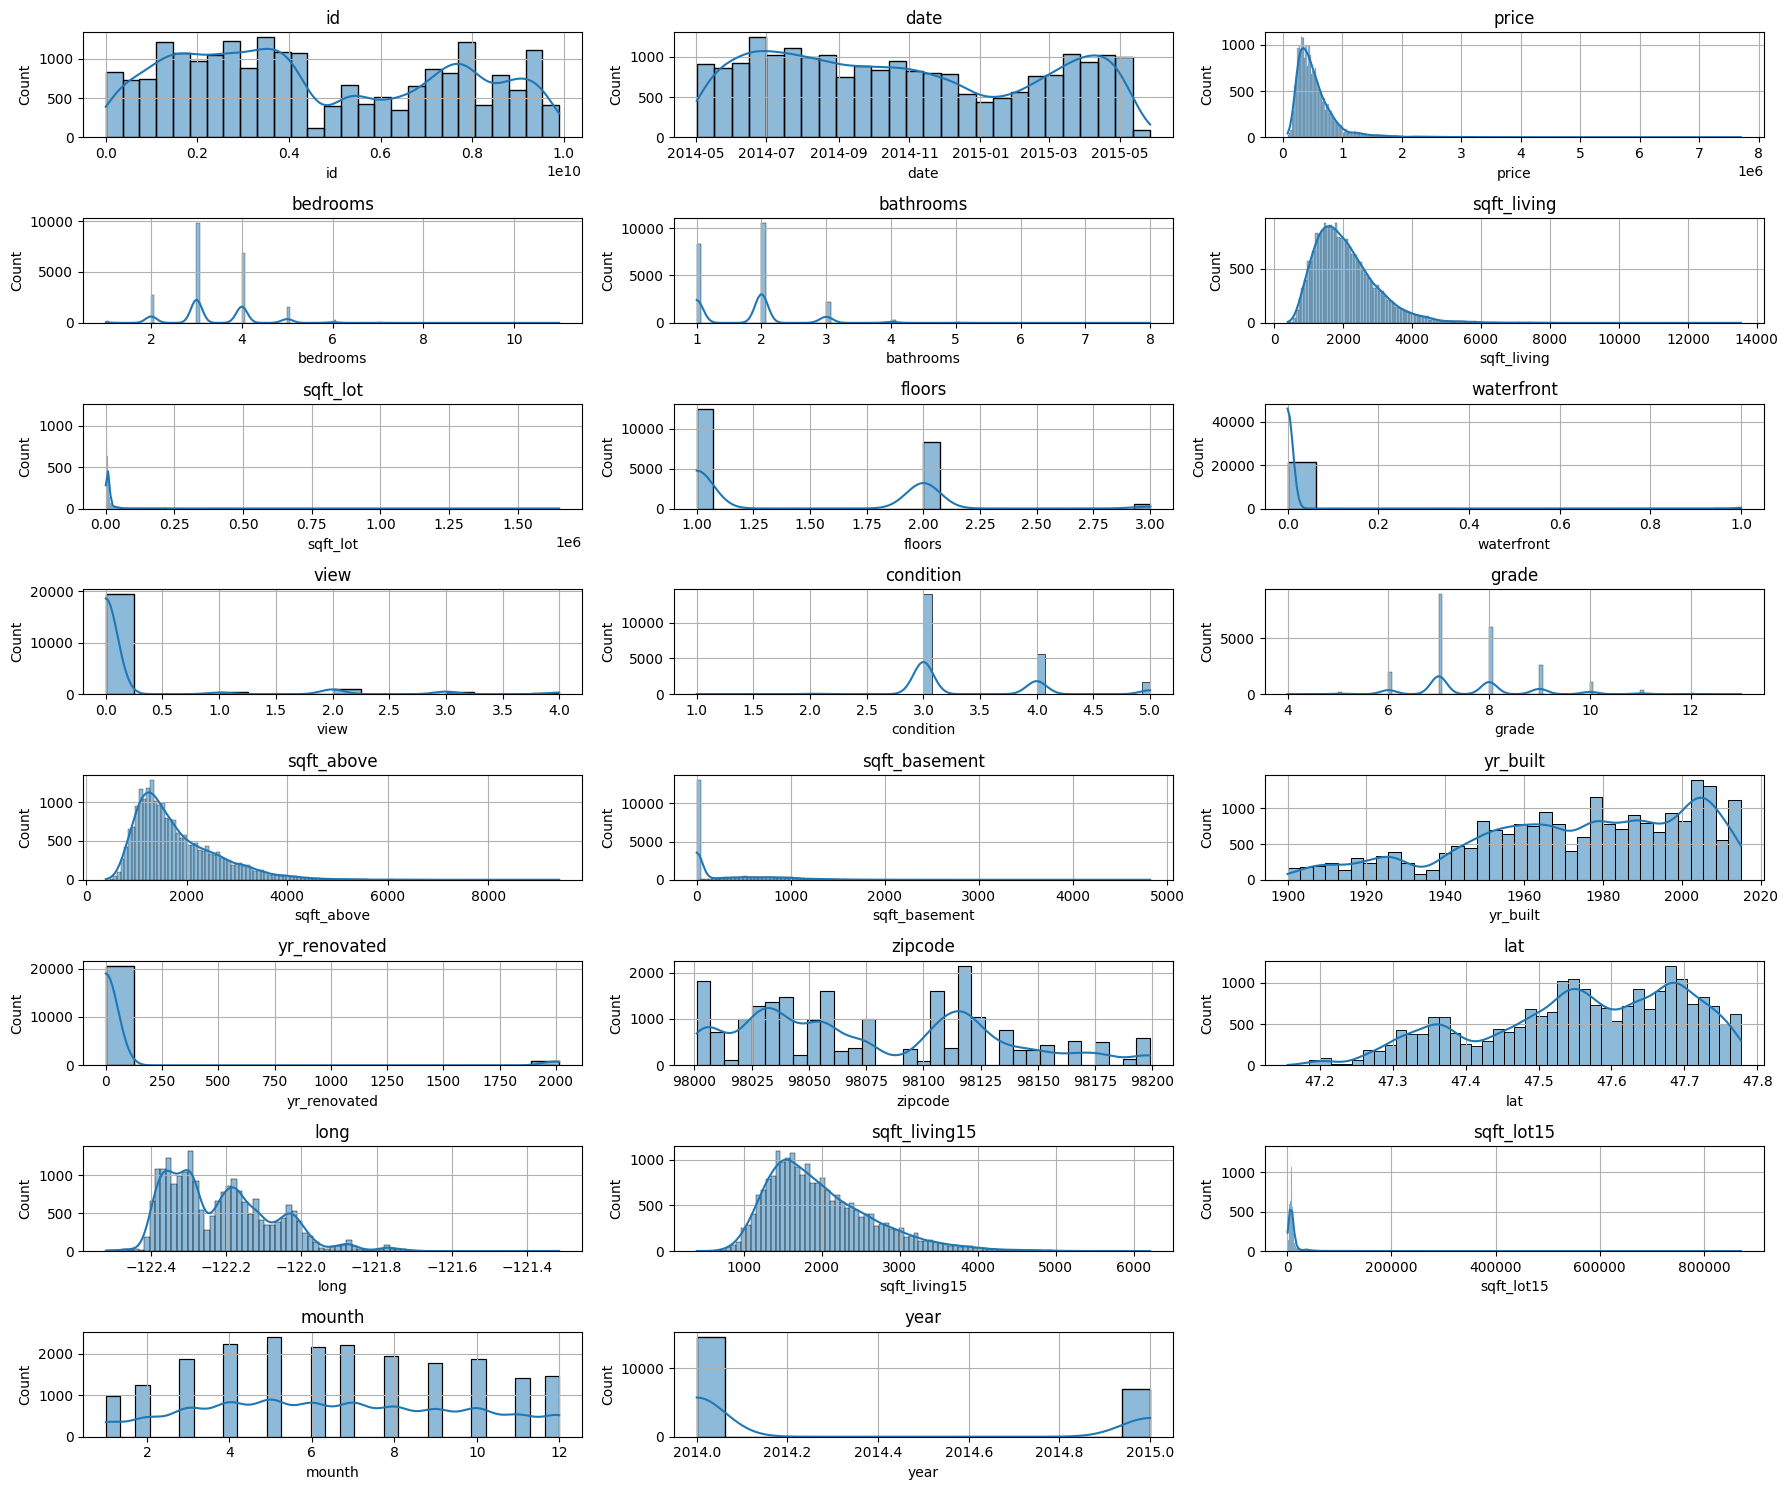

In [44]:
# Determine the number of columns to plot
num_cols = len(df.columns)

# Create a grid with the number of columns and rows based on the total number of features
fig, axes = plt.subplots(nrows=(num_cols // 3) + 1, ncols=3, figsize=(18, 15))  # Adjust rows and cols as needed

# Flatten the axes array to iterate over subplots easily
axes = axes.flatten()

# Plot each feature in its own subplot
for i, col in enumerate(df.columns):
    sns.histplot(df[col], kde=True, ax=axes[i])  # Plot the histogram with KDE on the current subplot
    axes[i].set_title(f'{col}')                  # Set the title for each subplot
    axes[i].set_xlabel(col)                      # Set the x-axis label for each subplot
    axes[i].grid(True)

# Remove any empty subplots if the number of columns is not a perfect multiple of rows x columns
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])  # Remove unused subplots

# Adjust layout and display the combined figure
plt.tight_layout()
plt.show()


#### Note

Most of the columns, including the `price` column, are `right-skewed`. However, I will keep the data as it is because this skewness is an important characteristic of the dataset.

---
## Validate Logical Relationships

In [45]:
df['id'].nunique() - len(df)  # Result: 176 duplicates in the 'id' column.

# Check the number of fully duplicated rows.
df.duplicated().sum()  # Result: 0 full-row duplicates, indicating partial duplicates in some columns.

# Display a sample of rows with duplicated 'id' values, keeping all occurrences.
df[df['id'].duplicated(keep=False)].sort_values('id').head(10)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,mounth,year
2497,1000102,2015-04-22,300000.0,6,3,2400,9373,2,0,0,3,7,2400,0,1991,0,98002,47.3262,-122.214,2060,7316,4,2015
2496,1000102,2014-09-16,280000.0,6,3,2400,9373,2,0,0,3,7,2400,0,1991,0,98002,47.3262,-122.214,2060,7316,9,2014
16815,7200179,2015-04-24,175000.0,2,1,840,12750,1,0,0,3,6,840,0,1925,0,98055,47.4840,-122.211,1480,6969,4,2015
16814,7200179,2014-10-16,150000.0,2,1,840,12750,1,0,0,3,6,840,0,1925,0,98055,47.4840,-122.211,1480,6969,10,2014
11433,109200390,2014-08-20,245000.0,3,1,1480,3900,1,0,0,4,7,1480,0,1980,0,98023,47.2977,-122.367,1830,6956,8,2014
11434,109200390,2014-10-20,250000.0,3,1,1480,3900,1,0,0,4,7,1480,0,1980,0,98023,47.2977,-122.367,1830,6956,10,2014
12418,123039336,2014-12-08,244900.0,1,1,620,8261,1,0,0,3,5,620,0,1939,0,98106,47.5138,-122.364,1180,8244,12,2014
12417,123039336,2014-06-11,148000.0,1,1,620,8261,1,0,0,3,5,620,0,1939,0,98106,47.5138,-122.364,1180,8244,6,2014
7793,251300110,2015-01-14,358000.0,3,2,2510,12013,2,0,0,3,8,2510,0,1988,0,98003,47.3473,-122.314,1870,8017,1,2015
7792,251300110,2014-07-31,225000.0,3,2,2510,12013,2,0,0,3,8,2510,0,1988,0,98003,47.3473,-122.314,1870,8017,7,2014


### Note
It turned out that some `id` values were duplicated, but after analyzing the duplicated rows, it became clear that these are just `price updates` over time. Therefore, I decided to keep only the last row for each `id`, `sorted by the date` column.

In [46]:
df = df.sort_values(by=['id', 'date']).drop_duplicates(subset='id', keep='last')
df['id'].duplicated().sum()

0

In [47]:
print('Check if sqft_above + sqft_basement = sqft_living : ',(df['sqft_above'] + df['sqft_basement'] != df['sqft_living']).sum() == False)


print('zip code list : ', (df["zipcode"].astype(str).str[:2] ).unique())


Check if sqft_above + sqft_basement = sqft_living :  True
zip code list :  ['98']


### Note

All good.

---
## Exporting Cleaned Data

In [49]:
# Exporting only the original columns to a CSV file
df[original_columns].to_csv('cleaned_housing_data.csv', index=False) 